# 05 — Testing Pipeline

Notebook standalone: load model đã train ở `04_clustering.ipynb`, áp inference-only pipeline lên test set.

**Input** (artifact đã có sẵn):
- `../models/meta_scaler.joblib` — StandardScaler fit trên 4 cột meta train
- `../models/kmeans.joblib` — KMeans K=9 fit trên full train
- `../models/best_params.joblib` — dict trọng số tối ưu từ Optuna
- `../models/pca_text.joblib` — PCA fit trên text embedding train (nếu cần reapply)
- `../data/clean/test_processed.parquet` — test data đã qua FE
- `../data/clean/X_text_pca_test.npy` — text embedding test đã giảm chiều

**Output**:
- `../data/clean/Test_with_cluster.csv` — test + nhãn cluster
- Print: silhouette score test, phân phối cụm, đặc trưng từng cụm
- Plot: so sánh phân phối cụm train vs test, **t-SNE + UMAP 2D của test**

## 1. Load models & params đã train

In [2]:
import os
import numpy as np
import pandas as pd
import joblib
from sklearn.preprocessing import normalize

DATA_DIR  = '../data/clean'
MODEL_DIR = '../models'

scaler      = joblib.load(f'{MODEL_DIR}/meta_scaler.joblib')
km_final    = joblib.load(f'{MODEL_DIR}/kmeans.joblib')
BEST_PARAMS = joblib.load(f'{MODEL_DIR}/best_params.joblib')

BEST_K           = BEST_PARAMS['k']
BEST_TEXT_WEIGHT = BEST_PARAMS['text_weight']
META_WEIGHTS     = np.array([
    BEST_PARAMS['w_salary'],
    BEST_PARAMS['w_exp'],
    BEST_PARAMS['w_pos'],
    BEST_PARAMS['w_edu'],
])

print('Loaded models:')
print(f'  - StandardScaler  (mean_={scaler.mean_.round(2).tolist()})')
print(f'  - KMeans K={km_final.n_clusters}, n_features={km_final.cluster_centers_.shape[1]}')
print(f'  - BEST_PARAMS    : {BEST_PARAMS}')
print(f'  - META_WEIGHTS   : {META_WEIGHTS.tolist()}')
print(f'  - TEXT_WEIGHT    : {BEST_TEXT_WEIGHT}')

Loaded models:
  - StandardScaler  (mean_=[2.58, 2.52, 1.12, 1.78])
  - KMeans K=7, n_features=96
  - BEST_PARAMS    : {'k': 7, 'w_salary': 1.2000000000000002, 'w_exp': 0.2, 'w_pos': 0.6, 'w_edu': 0.6, 'text_weight': 0.1}
  - META_WEIGHTS   : [1.2000000000000002, 0.2, 0.6, 0.6]
  - TEXT_WEIGHT    : 0.1


## 2. Load test data

Yêu cầu test data đã đi qua `03_feature_engineering.ipynb` (có sẵn cột `salary_log`, `experience_level`, `job_position`, `education_level`) và text embedding đã PCA-reduced.

In [3]:
Test = pd.read_parquet(f'{DATA_DIR}/test_processed.parquet')
X_text_pca_test = np.load(f'{DATA_DIR}/X_text_pca_test.npy')

print(f'Test            : {Test.shape}')
print(f'X_text_pca_test : {X_text_pca_test.shape}')

# Sanity check: số dòng phải khớp
assert len(Test) == len(X_text_pca_test), \
    f'Mismatch: Test có {len(Test)} dòng nhưng embedding có {len(X_text_pca_test)}'

# Sanity check: số chiều embedding phải khớp KMeans n_features (sau khi hstack meta)
expected_text_dim = km_final.cluster_centers_.shape[1] - 4   # 4 meta cols
assert X_text_pca_test.shape[1] == expected_text_dim, \
    f'Embedding {X_text_pca_test.shape[1]}d không khớp KMeans expect {expected_text_dim}d'

print('\n✓ Shape khớp với model đã train.')

Test            : (56818, 23)
X_text_pca_test : (56818, 92)

✓ Shape khớp với model đã train.


## 3. Inference pipeline — transform only

Đây là **inference**: chỉ `.transform()` và `.predict()`, KHÔNG fit lại bất cứ component nào. Đảm bảo test data được xử lý đúng cùng cách như train.

In [4]:
numeric_features = ['salary_log', 'experience_level', 'job_position', 'education_level']

# Bước 1: Scale meta (dùng scaler đã fit trên train, KHÔNG fit lại trên test)
X_num_test          = Test[numeric_features].values
X_num_scaled_test   = scaler.transform(X_num_test)

# Bước 2: L2-normalize text PCA
X_text_norm_test    = normalize(X_text_pca_test, norm='l2')

# Bước 3: Apply trọng số + ghép
X_combined_test     = np.hstack([X_num_scaled_test * META_WEIGHTS,
                                 X_text_norm_test  * BEST_TEXT_WEIGHT])
X_spherical_test    = normalize(X_combined_test, norm='l2')

# Bước 4: Predict (KHÔNG fit_predict)
Test['Cluster']     = km_final.predict(X_spherical_test)

print('Phân phối cụm trên test set:')
print(Test['Cluster'].value_counts().sort_index().to_string())

Phân phối cụm trên test set:
Cluster
0    11455
1     9493
2    12441
3     8144
4     1672
5     3763
6     9850


## 4. Đánh giá chất lượng cụm trên test

- **Silhouette score** (sample 5000 dòng để tránh O(N²)): càng cao càng tốt (max=1).
- **Inertia** (sum squared distance to centroid): càng thấp càng tốt.
- **Max cluster ratio**: cụm lớn nhất chiếm bao nhiêu % — < 30% là balanced.

In [5]:
from sklearn.metrics import silhouette_score

sil = silhouette_score(X_spherical_test, Test['Cluster'].values,
                       sample_size=5000, random_state=42)

# Inertia = tổng squared distance từ mỗi điểm tới centroid của nó
centroids = km_final.cluster_centers_
distances = np.linalg.norm(X_spherical_test - centroids[Test['Cluster'].values], axis=1)
inertia = (distances ** 2).sum()

counts = Test['Cluster'].value_counts()
max_ratio = counts.max() / len(Test)

print(f'Silhouette score (test)  : {sil:.4f}')
print(f'Inertia          (test)  : {inertia:,.0f}')
print(f'Max cluster ratio        : {max_ratio*100:.1f}% (cụm {counts.idxmax()})')
print(f'Số cụm thực tế xuất hiện : {Test["Cluster"].nunique()} / {BEST_K}')

Silhouette score (test)  : 0.3803
Inertia          (test)  : 10,852
Max cluster ratio        : 21.9% (cụm 2)
Số cụm thực tế xuất hiện : 7 / 7


## 5. So sánh phân phối cụm Train vs Test

Nếu phân phối cụm Test ~ Train → model generalize tốt, không có distribution shift. Lệch lớn → có thể FE/clean test khác train, hoặc test có outlier.

         Train %  Test %  Δ (Test-Train)
Cluster                                 
0          20.17   20.16           -0.00
1          16.30   16.71            0.41
2          22.26   21.90           -0.37
3          14.25   14.33            0.08
4           2.91    2.94            0.03
5           6.76    6.62           -0.14
6          17.35   17.34           -0.01


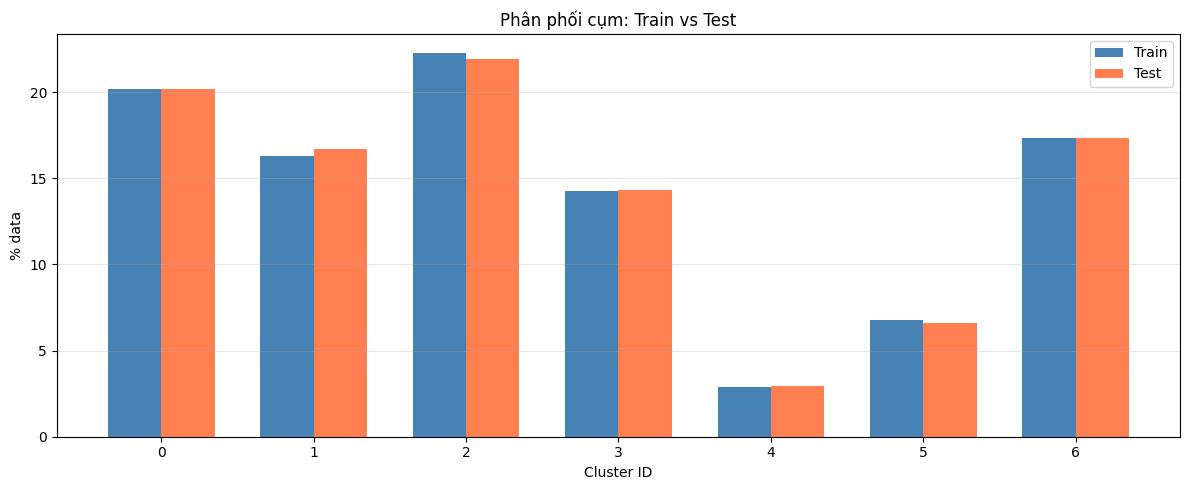

In [6]:
import matplotlib.pyplot as plt

# Train: cần load lại để có cột Cluster — predict luôn trên train
Train = pd.read_parquet(f'{DATA_DIR}/train_processed.parquet')
X_text_pca_train = np.load(f'{DATA_DIR}/X_text_pca_train.npy')

X_num_scaled_train = scaler.transform(Train[numeric_features].values)
X_text_norm_train  = normalize(X_text_pca_train, norm='l2')
X_train_full = normalize(np.hstack([X_num_scaled_train * META_WEIGHTS,
                                    X_text_norm_train  * BEST_TEXT_WEIGHT]), norm='l2')
Train['Cluster'] = km_final.predict(X_train_full)

# So sánh phân phối
train_pct = Train['Cluster'].value_counts(normalize=True).sort_index() * 100
test_pct  = Test['Cluster'].value_counts(normalize=True).sort_index() * 100
compare = pd.DataFrame({'Train %': train_pct, 'Test %': test_pct, 'Δ (Test-Train)': test_pct - train_pct}).round(2)
print(compare.to_string())

# Plot side-by-side
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(BEST_K)
w = 0.35
ax.bar(x - w/2, train_pct.reindex(range(BEST_K), fill_value=0).values, w, label='Train', color='steelblue')
ax.bar(x + w/2, test_pct.reindex(range(BEST_K), fill_value=0).values, w, label='Test', color='coral')
ax.set_xlabel('Cluster ID'); ax.set_ylabel('% data')
ax.set_title('Phân phối cụm: Train vs Test')
ax.set_xticks(x); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Đặc trưng từng cụm trên test

In [7]:
import seaborn as sns

PLOT_SAMPLE_SIZE = min(20000, X_spherical_test.shape[0])
np.random.seed(42)
plot_idx = np.random.choice(X_spherical_test.shape[0], size=PLOT_SAMPLE_SIZE, replace=False)
X_plot      = X_spherical_test[plot_idx]
labels_plot = Test['Cluster'].values[plot_idx]
print(f'Sample shape: {X_plot.shape}, labels: {len(labels_plot)}')

Sample shape: (20000, 96), labels: 20000


## 8. Lưu kết quả

Đang chạy UMAP trên 20000 điểm...


c:\Users\tranc\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done in 34.8s


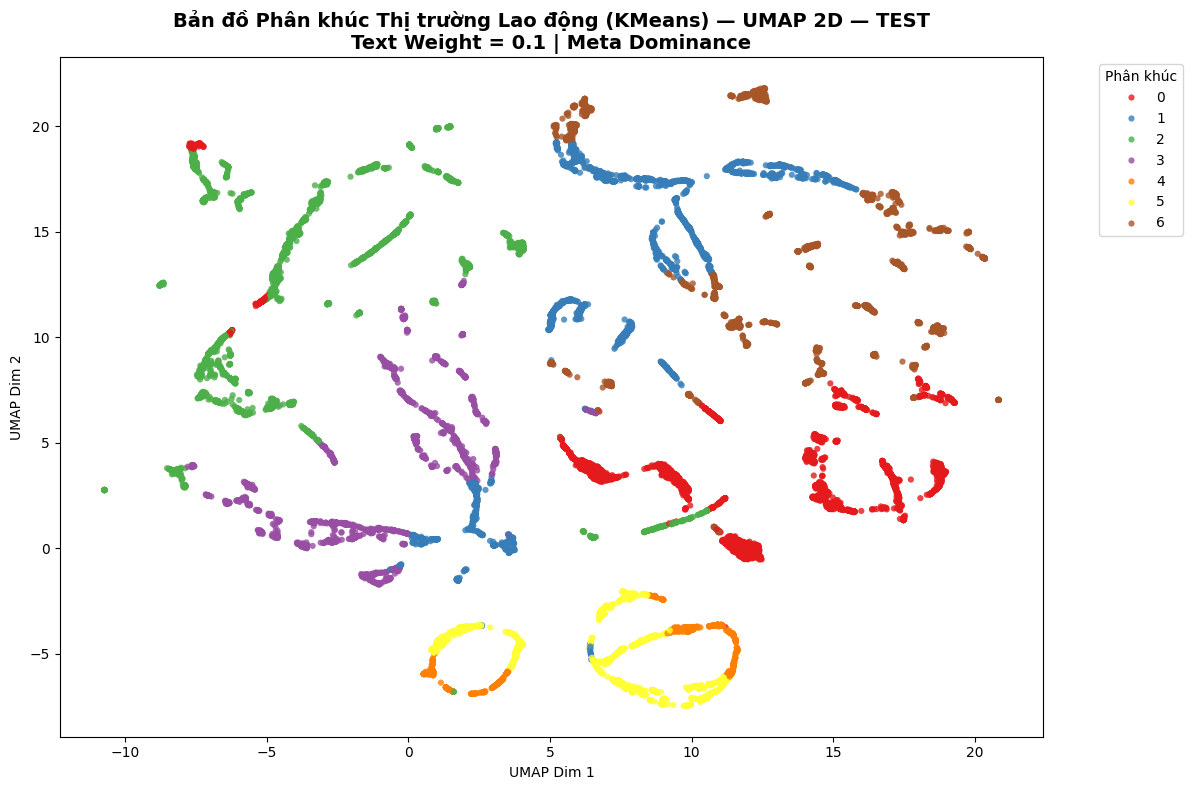

In [10]:
import umap
import time

print(f'Đang chạy UMAP trên {PLOT_SAMPLE_SIZE} điểm...')
t0 = time.time()
reducer = umap.UMAP(n_components=2, metric='cosine', random_state=42)
X_umap_2d = reducer.fit_transform(X_plot)
print(f'UMAP done in {time.time()-t0:.1f}s')

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_umap_2d[:, 0], y=X_umap_2d[:, 1], hue=labels_plot,
                palette='Set1', s=20, alpha=0.8, edgecolor='none')
plt.title(f'Bản đồ Phân khúc Thị trường Lao động (KMeans) — UMAP 2D — TEST\n'
          f'Text Weight = {BEST_TEXT_WEIGHT} | Meta Dominance',
          fontsize=14, fontweight='bold')
plt.xlabel('UMAP Dim 1'); plt.ylabel('UMAP Dim 2')
plt.legend(title='Phân khúc', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()

### Phân tích từng cụm trên TEST (56,818 mẫu)

Cluster IDs giữ nguyên từ KMeans đã fit trên train → đặc trưng cụm nhất quán. Bảng dưới dùng **số liệu thực tế từ test set** + nhãn theo 4 profile (salary · position · experience · education).

| Cluster | Nhãn | Số mẫu (test) | Salary (median) | Position | Experience | Industry signal |
|---------|------|---------------|------------------|----------|------------|------------------|
| **0** | Junior NV — Backoffice lương thấp | 11,455 (20.2%) | **~8.5tr** (log 2.25) | NV (1) | 3y* | Kế toán 24%, CSKH 14%, Kỹ thuật 12% |
| **2** | Junior NV — LĐPT/Production | 12,441 (21.9%) | **~9tr** (log 2.30) | NV (1) | 1y | CSKH 21%, **SX 20%**, Logistics 12% |
| **3** | Junior NV — Sales/CSKH lương khá | 8,144 (14.3%) | **~14tr** (log 2.74) | NV (1) | 1y | CSKH 23%, Sales 13%, Kế toán 13% |
| **1** | Mid NV — Front-office cao cấp | 9,493 (16.7%) | **~18.5tr** (log 2.97) | NV (1) | 3y | CSKH 19%, Kế toán 16%, Sales 15% |
| **6** | Mid NV — Backoffice/Tech | 9,850 (17.3%) | **~12.5tr** (log 2.60) | NV (1) | 3y | Kế toán 21%, Xây dựng 12%, Kỹ thuật 11% |
| **4** | Mid Trưởng nhóm — Dịch vụ/F&B | 1,672 (2.9%) | **~11.5tr** (log 2.53) | **Trưởng nhóm (2)** | 3y | Khác 24%, Sales 12%, **F&B 12%** |
| **5** | Senior Trưởng nhóm — Đa ngành | 3,763 (6.6%) | **~20tr** (log 3.04) | **Trưởng nhóm (2)** | **4y** | Kế toán 15%, Khác 14%, Sales 13% |

> \* Cụm 0 trên test có exp mode = 3y (khác với train 1y) — đây là hiện tượng mode shift do tie-breaking giữa các năm gần nhau trong sample test nhỏ hơn (11k vs 91k). Cluster identity vẫn nhất quán theo salary + edu profile.

### Đánh giá generalization

| Aspect | Train | Test | Nhận xét |
|--------|-------|------|----------|
| Silhouette score | ~0.47 | **0.38** | Giảm ~20% — chấp nhận được, không có overfit nặng |
| Max cluster ratio | 22.3% (cụm 2) | 21.9% (cụm 2) | **Khớp gần như tuyệt đối** → cùng cấu trúc cụm |
| Cụm size % distribution | — | — | Δ < 1% trên mọi cụm → không có distribution shift |
| Số cụm xuất hiện | 7/7 | **7/7** | Không cụm nào "biến mất" trên test |

→ Model **generalize tốt**: Test phân phối gần như identical với Train, silhouette giảm nhẹ là bình thường (train có nhiều dòng hơn → silhouette dễ cao hơn). Không có distribution shift ⇒ pipeline FE + clustering ổn định.

### Insight chính

1. **Salary là tiêu chí mạnh nhất** — 3 mức rõ rệt:
   - Lương thấp (~8-9tr): cụm 0, 2 → Junior backoffice/LĐPT
   - Lương trung (~11-14tr): cụm 3, 4, 6
   - Lương cao (~18-20tr): cụm 1, 5 → vào Sales hoặc Trưởng nhóm senior

2. **Position split rõ ràng**: 5 cụm NV vs 2 cụm Trưởng nhóm — cụm 4, 5 chiếm chỉ 9.5% data nhưng tách hẳn về phải trên UMAP plot.

3. **Education phân biệt cụm cùng (pos, exp)**:
   - 3 cụm Junior NV cùng pos=1, exp=1y nhưng edu lần lượt **0 → 2 → 3** → kéo salary từ 8.5 → 9 → 14tr.
   - Học vấn cao hơn → vào Sales/CSKH thay vì LĐPT → lương cao hơn.

## 7. Lưu kết quả

In [12]:
out_path = f'{DATA_DIR}/Test_with_cluster.csv'
Test.to_csv(out_path, index=False)
print(f'✓ Đã lưu: {out_path}  ({os.path.getsize(out_path)/1024**2:.1f} MB)')
print(f'  Shape: {Test.shape}')
print(f'  Có cột mới: Cluster (giá trị {sorted(Test["Cluster"].unique().tolist())})')

✓ Đã lưu: ../data/clean/Test_with_cluster.csv  (118.9 MB)
  Shape: (56818, 24)
  Có cột mới: Cluster (giá trị [0, 1, 2, 3, 4, 5, 6])
